# ChemProp | ESOL Aqueous Solubility Prediction

**Goal:** Predict experimentally measured aqueous solubility, expressed as **log₁₀(mol/L)**, from molecular structures. This notebook explores the Delaney ESOL dataset, computes RDKit descriptors, and compares regression models.

**Workflow:** Data exploration → molecular representations → descriptors → quality checks → model training → evaluation → feature importance.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

## 1. Load the ESOL dataset

Read the CSV file containing molecular structures (**SMILES**), measured aqueous solubilities, and reference descriptors/predictions.

In [3]:
df = pd.read_csv("../data/delaney-processed.csv")

In [4]:
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


## 2. Explore the data

Inspect column types, descriptive statistics, dataset size, and column names before modeling. The target is **measured log solubility in mols per litre**.

**Note:** The first `df.describe` cell displays the method itself; `df.describe()` executes it.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Compound ID                                      1128 non-null   object 
 1   ESOL predicted log solubility in mols per litre  1128 non-null   float64
 2   Minimum Degree                                   1128 non-null   int64  
 3   Molecular Weight                                 1128 non-null   float64
 4   Number of H-Bond Donors                          1128 non-null   int64  
 5   Number of Rings                                  1128 non-null   int64  
 6   Number of Rotatable Bonds                        1128 non-null   int64  
 7   Polar Surface Area                               1128 non-null   float64
 8   measured log solubility in mols per litre        1128 non-null   float64
 9   smiles                        

In [6]:
df.describe

<bound method NDFrame.describe of          Compound ID  ESOL predicted log solubility in mols per litre  \
0          Amigdalin                                           -0.974   
1           Fenfuram                                           -2.885   
2             citral                                           -2.579   
3             Picene                                           -6.618   
4          Thiophene                                           -2.232   
...              ...                                              ...   
1123       halothane                                           -2.608   
1124          Oxamyl                                           -0.908   
1125       Thiometon                                           -3.323   
1126  2-Methylbutane                                           -2.245   
1127        Stirofos                                           -4.320   

      Minimum Degree  Molecular Weight  Number of H-Bond Donors  \
0                  1  

In [7]:
df.describe()

,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-2.988192,1.058511,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,1.683220,0.238560,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,-9.702000,0.000000,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,-3.948250,1.000000,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,-2.870000,1.000000,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,-1.843750,1.000000,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,1.091000,2.000000,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


In [8]:
df.shape

(1128, 10)

In [9]:
df.columns.tolist()

['Compound ID',
 'ESOL predicted log solubility in mols per litre',
 'Minimum Degree',
 'Molecular Weight',
 'Number of H-Bond Donors',
 'Number of Rings',
 'Number of Rotatable Bonds',
 'Polar Surface Area',
 'measured log solubility in mols per litre',
 'smiles']

## 3. Identify the target and inspect molecular structures

Select the SMILES column and experimental logS target. Use **RDKit** to parse a SMILES string into a molecule and render its structure. Canonical SMILES gives a standardized representation.

In [10]:
smiles_col = "smiles"
target_col = "measured log solubility in mols per litre"

In [11]:
df[[smiles_col, target_col]].head()

,smiles,measured log solubility in mols per litre
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


In [12]:
smiles = df.loc[0, "smiles"]

mol = Chem.MolFromSmiles(smiles)

mol

In [13]:
print(Chem.MolToSmiles(mol))

N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


## 4. Calculate molecular descriptors with RDKit

For each molecule, calculate **molecular weight (MolWt), calculated partition coefficient (LogP), hydrogen-bond donors (HBD), hydrogen-bond acceptors (HBA), topological polar surface area (TPSA), rotatable bonds, and ring count**.

These numerical features describe aspects of molecular size, lipophilicity, polarity, and flexibility.

In [14]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [15]:
calculate_descriptors("CCO")

{'MolWt': 46.069,
 'LogP': -0.0014000000000000123,
 'HBD': 1,
 'HBA': 1,
 'TPSA': 20.23,
 'RotatableBonds': 0,
 'Rings': 0}

In [16]:
Compound_ID = df.loc[0, "Compound ID"]

print(Compound_ID)

Amigdalin


In [17]:
df[[smiles_col, target_col]].head()


,smiles,measured log solubility in mols per litre
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


In [18]:
smiles = df.loc[0, "smiles"]

mol = Chem.MolFromSmiles(smiles)

mol

In [19]:
print(Chem.MolToSmiles(mol))

N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


In [20]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [21]:
calculate_descriptors("CCO")

{'MolWt': 46.069,
 'LogP': -0.0014000000000000123,
 'HBD': 1,
 'HBA': 1,
 'TPSA': 20.23,
 'RotatableBonds': 0,
 'Rings': 0}

## 5. Build the descriptor table and check data quality

Apply the descriptor function to all SMILES strings, combine the results with the target, inspect missing values, and summarize distributions.

**Interpretation:** A scatter plot of LogP versus measured logS helps visualize whether more lipophilic molecules tend to be less soluble in water.

In [22]:
descriptor_df = df["smiles"].apply(calculate_descriptors).apply(pd.Series)

In [23]:
descriptor_df.head()

,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [24]:
descriptor_df.shape

(1128, 7)

In [25]:
data = pd.concat(
    [
        df[[smiles_col, target_col]].reset_index(drop=True),
        descriptor_df.reset_index(drop=True)
    ],
    axis=1
)

In [26]:
data.head()

,smiles,measured log solubility in mols per litre,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,-3.30,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),-2.06,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,c1ccsc1,-1.33,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [27]:
data.isna().sum()

smiles                                       0
measured log solubility in mols per litre    0
MolWt                                        0
LogP                                         0
HBD                                          0
HBA                                          0
TPSA                                         0
RotatableBonds                               0
Rings                                        0
dtype: int64

In [28]:
data.describe()

,measured log solubility in mols per litre,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-3.050102,203.937074,2.447520,0.701241,2.111702,34.872881,2.177305,1.390957
std,2.096441,102.738077,1.852875,1.089727,2.153375,35.383593,2.640974,1.318286
min,-11.600000,16.043000,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-4.317500,121.183000,1.414900,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-2.860000,182.179000,2.339000,0.000000,2.000000,26.300000,1.000000,1.000000
75%,-1.600000,270.372000,3.402200,1.000000,3.000000,55.440000,3.000000,2.000000
max,1.580000,780.949000,10.388600,11.000000,16.000000,268.680000,23.000000,8.000000


In [29]:
data["MolWt"].isna().sum()

0

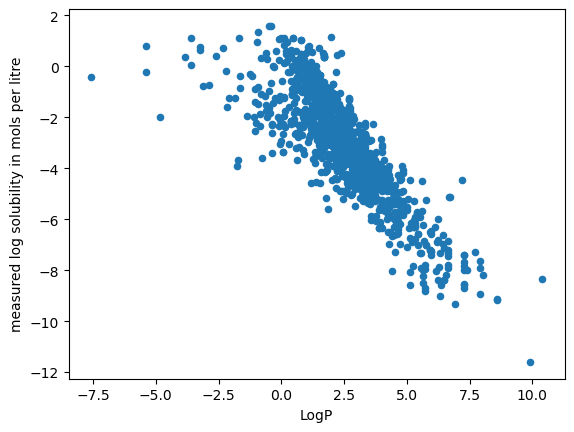

In [30]:
data.plot.scatter(
    x="LogP",
    y=target_col
)

plt.show()

## 6. Evaluate the dataset’s existing ESOL predictions

Compare the supplied **ESOL predicted log solubility** values against experimental measurements using error metrics. This is a reference comparison, not a newly trained model.

In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

pred = df["ESOL predicted log solubility in mols per litre"]
actual = df[target_col]

mae = mean_absolute_error(actual, pred)
rmse = np.sqrt(mean_squared_error(actual, pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.6978617021276595
RMSE: 0.9101322725549837


## 7. Prepare features for machine learning

The descriptor function and table are repeated below as part of the modeling workflow. Define **X** as seven RDKit descriptors and **y** as measured logS; verify that neither contains missing values.

In [32]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [33]:
descriptor_df = (
    df["smiles"]
    .apply(calculate_descriptors)
    .apply(pd.Series)
)

descriptor_df.head()

,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [34]:
feature_cols = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "RotatableBonds",
    "Rings"
]

In [35]:
X = data[feature_cols]
y = data["measured log solubility in mols per litre"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (1128, 7)
y shape: (1128,)


,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [36]:
print(X.isna().sum())
print("Missing targets:", y.isna().sum())

MolWt             0
LogP              0
HBD               0
HBA               0
TPSA              0
RotatableBonds    0
Rings             0
dtype: int64
Missing targets: 0


## 8. Split the dataset into training and test sets

Use an **80/20 random split** with `random_state=42` for reproducibility. Train on the training set and report predictive performance on the held-out test set.

**Limitation:** Random splits may place structurally similar compounds in both sets. Scaffold-based validation will be useful later.

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training molecules:", len(X_train))
print("Testing molecules:", len(X_test))

Training molecules: 902
Testing molecules: 226


## 9. Baseline model: Linear Regression

Fit a linear relationship between molecular descriptors and measured logS. Evaluate with **MAE**, **RMSE**, and **R²**, then plot predicted versus measured values and inspect coefficients.

**Caution:** Coefficients are sensitive to feature scale and correlation, so their raw magnitudes are not a direct ranking of chemical importance.

In [38]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [39]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[-1.74683169 -2.37820985 -1.97578791 -1.74683169 -6.44963896 -1.72579052
 -3.94679341 -1.74507019 -8.24418136 -3.04139731]


In [40]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

MAE: 0.815
RMSE: 1.073
R²: 0.756


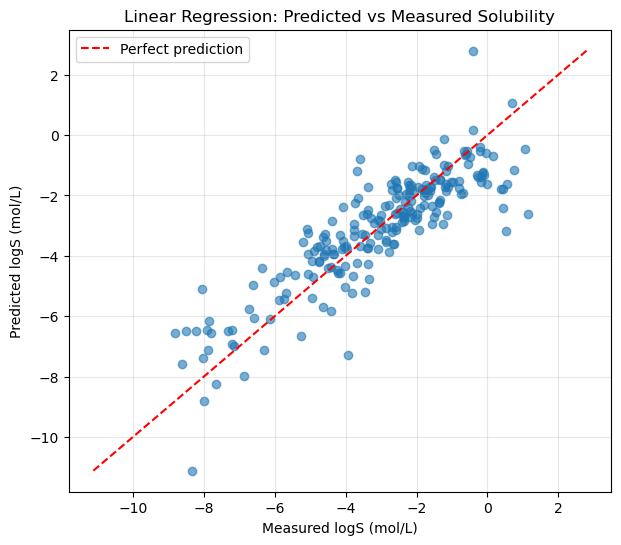

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Measured logS (mol/L)")
plt.ylabel("Predicted logS (mol/L)")
plt.title("Linear Regression: Predicted vs Measured Solubility")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [42]:
import pandas as pd

coefficients = pd.DataFrame({
    "Descriptor": feature_cols,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient"
)

print("Intercept:", model.intercept_)
display(coefficients)

Intercept: 0.1942615777238439


,Descriptor,Coefficient
1,LogP,-0.835780
6,Rings,-0.225097
5,RotatableBonds,-0.061711
2,HBD,-0.042045
4,TPSA,-0.013436
0,MolWt,-0.003291
3,HBA,0.198263


## 10. Nonlinear model: Random Forest

Train a **300-tree Random Forest Regressor** using the same features and train/test split. This model can capture nonlinear relationships and interactions among descriptors.

In [43]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [44]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE: {rf_mae:.3f}")
print(f"Random Forest RMSE: {rf_rmse:.3f}")
print(f"Random Forest R²: {rf_r2:.3f}")

Random Forest MAE: 0.561
Random Forest RMSE: 0.810
Random Forest R²: 0.861


## 11. Compare the two models

Compare test-set error and fit quality. **Lower MAE/RMSE** and **higher R²** indicate better predictive performance on this particular split.

Previously observed results: **Linear Regression:** MAE ≈ 0.815, RMSE ≈ 1.073, R² ≈ 0.756. **Random Forest:** MAE ≈ 0.561, RMSE ≈ 0.810, R² ≈ 0.861.

In [45]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R²": [r2, rf_r2]
})

display(comparison)

,Model,MAE,RMSE,R²
0,Linear Regression,0.815243,1.072849,0.756494
1,Random Forest,0.561375,0.809972,0.861206


In [46]:
print(comparison.to_string(index=False))

            Model      MAE     RMSE       R²
Linear Regression 0.815243 1.072849 0.756494
    Random Forest 0.561375 0.809972 0.861206


## 12. Random Forest built-in feature importance

Plot the forest’s impurity-based importance scores. These measure how much features contribute to reducing tree-split error, but can be biased by feature characteristics and correlations. **Importance is not causation.**

       Feature  Importance
           HBD    0.006539
           HBA    0.010740
RotatableBonds    0.010808
         Rings    0.011629
          TPSA    0.044005
         MolWt    0.098937
          LogP    0.817342


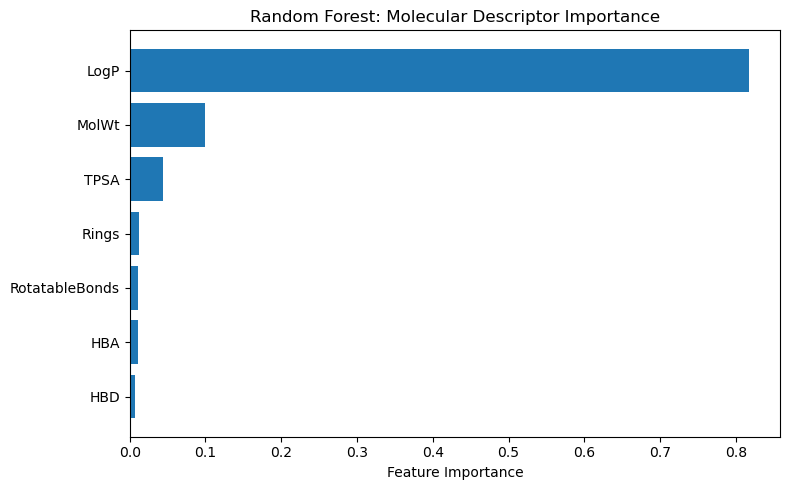

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=True
)

print(importance.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature Importance")
plt.title("Random Forest: Molecular Descriptor Importance")
plt.tight_layout()
plt.show()

## 13. Permutation importance on the test set

Shuffle each descriptor repeatedly and measure the resulting **increase in mean squared error (MSE)**. Larger increases indicate that the fitted model relies more heavily on that feature. Error bars show variation across permutations.

**Current finding:** LogP dominates the plot, with molecular weight a distant second. Near-zero importance does **not** mean hydrogen bonding or other properties are chemically irrelevant.

In [48]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": result.importances_mean,
    "Std": result.importances_std
})

perm_df = perm_df.sort_values(
    by="Importance",
    ascending=False
)

print(perm_df.to_string(index=False))

       Feature  Importance      Std
          LogP    6.988512 0.511079
         MolWt    0.468431 0.079828
          TPSA    0.122935 0.025904
         Rings    0.086740 0.012368
RotatableBonds    0.019352 0.007177
           HBA    0.012060 0.008011
           HBD    0.005732 0.006383


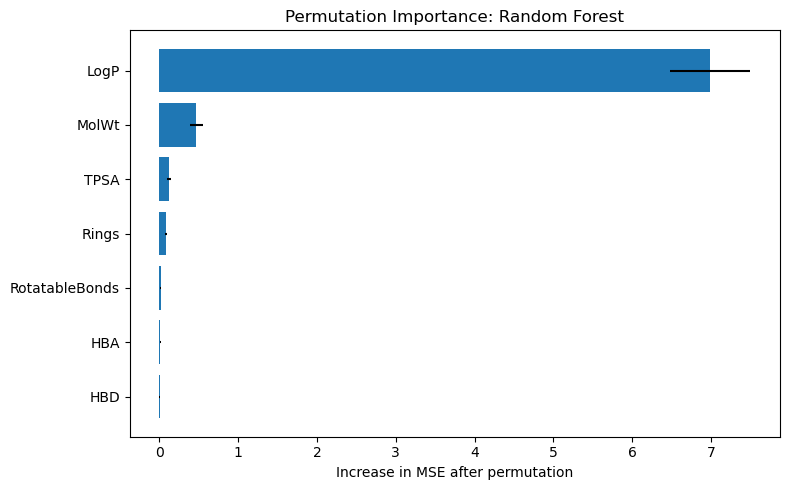

In [49]:
plt.figure(figsize=(8, 5))

plt.barh(
    perm_df["Feature"],
    perm_df["Importance"],
    xerr=perm_df["Std"]
)

plt.gca().invert_yaxis()
plt.xlabel("Increase in MSE after permutation")
plt.title("Permutation Importance: Random Forest")
plt.tight_layout()
plt.show()

## 14. Next experiments

- **Ablation:** Retrain without LogP to investigate how much it contributes beyond other descriptors.
- **Cross-validation:** Compare models across multiple splits rather than relying on one test set.
- **Morgan fingerprints:** Represent molecular substructures directly.
- **Scaffold splitting:** Test generalization to different molecular frameworks.

**Scientific caution:** Because we have already examined this test set, subsequent feature-selection experiments on it are exploratory; reserve an untouched test set for a final assessment.

In [50]:

# Remove LogP from the molecular descriptors
features_no_logp = [col for col in feature_cols if col != "LogP"]

X_train_no_logp = X_train[features_no_logp]
X_test_no_logp = X_test[features_no_logp]

# Train a new Random Forest using the remaining descriptors
rf_no_logp = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_no_logp.fit(X_train_no_logp, y_train)

# Predict aqueous solubility
y_pred_no_logp = rf_no_logp.predict(X_test_no_logp)


In [51]:
print(features_no_logp)

['MolWt', 'HBD', 'HBA', 'TPSA', 'RotatableBonds', 'Rings']


In [52]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest (all features)", "Random Forest (without LogP)"],
    "MAE": [
        0.561375,
        mean_absolute_error(y_test, y_pred_no_logp)
    ],
    "RMSE": [
        0.809972,
        np.sqrt(mean_squared_error(y_test, y_pred_no_logp))
    ],
    "R²": [
        0.861206,
        r2_score(y_test, y_pred_no_logp)
    ]
})

print(comparison.to_string(index=False))


                       Model      MAE     RMSE       R²
Random Forest (all features) 0.561375 0.809972 0.861206
Random Forest (without LogP) 0.594500 0.900999 0.828256


In [53]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest (all features)", "Random Forest (without LogP)"],
    "MAE": [
        0.561375,
        mean_absolute_error(y_test, y_pred_no_logp)
    ],
    "RMSE": [
        0.809972,
        np.sqrt(mean_squared_error(y_test, y_pred_no_logp))
    ],
    "R²": [
        0.861206,
        r2_score(y_test, y_pred_no_logp)
    ]
})

print(comparison.to_string(index=False))


                       Model      MAE     RMSE       R²
Random Forest (all features) 0.561375 0.809972 0.861206
Random Forest (without LogP) 0.594500 0.900999 0.828256


In [54]:

from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

models = {
    "With LogP": (
        X_train,
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    ),
    "Without LogP": (
        X_train_no_logp,
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = []

for name, (features, model) in models.items():
    scores = cross_validate(
        model,
        features,
        y_train,
        cv=5,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R²": scores["test_R2"].mean(),
        "R² Std": scores["test_R2"].std()
    })

cv_results = pd.DataFrame(results)
print(cv_results.to_string(index=False))


       Model      MAE     RMSE       R²   R² Std
   With LogP 0.500166 0.677896 0.891861 0.014912
Without LogP 0.623962 0.869843 0.822409 0.024055


In [55]:

from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

models = {
    "With LogP": (
        X_train,
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    ),
    "Without LogP": (
        X_train_no_logp,
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = []

for name, (features, model) in models.items():
    scores = cross_validate(
        model,
        features,
        y_train,
        cv=5,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R²": scores["test_R2"].mean(),
        "R² Std": scores["test_R2"].std()
    })

cv_results = pd.DataFrame(results)
print(cv_results.to_string(index=False))


       Model      MAE     RMSE       R²   R² Std
   With LogP 0.500166 0.677896 0.891861 0.014912
Without LogP 0.623962 0.869843 0.822409 0.024055


In [56]:

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import numpy as np

generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fingerprint = generator.GetFingerprint(mol)

    array = np.zeros(1024, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fingerprint, array)

    return array

fingerprints = np.array([
    smiles_to_fingerprint(smiles)
    for smiles in data["smiles"]
])

print("Fingerprint matrix shape:", fingerprints.shape)


Fingerprint matrix shape: (1128, 1024)


In [57]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_fp_train, X_fp_test, y_fp_train, y_fp_test = train_test_split(
    fingerprints,
    y,
    test_size=0.2,
    random_state=42
)

rf_fp = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_fp.fit(X_fp_train, y_fp_train)

y_fp_pred = rf_fp.predict(X_fp_test)

print("MAE:", mean_absolute_error(y_fp_test, y_fp_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_fp_test, y_fp_pred)))
print("R²:", r2_score(y_fp_test, y_fp_pred))


MAE: 0.8806291038060591
RMSE: 1.1742187285480292
R²: 0.7083040101963691


In [58]:

# Combine molecular descriptors and Morgan fingerprints
X_combined = np.hstack([
    X.to_numpy(),
    fingerprints
])

print("Combined feature matrix:", X_combined.shape)


Combined feature matrix: (1128, 1031)


In [59]:

from sklearn.model_selection import cross_validate, train_test_split
from sklearn.ensemble import RandomForestRegressor

# Reproduce the original 80/20 split
X_combined_train, _, y_combined_train, _ = train_test_split(
    X_combined,
    y,
    test_size=0.2,
    random_state=42
)

combined_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

scores = cross_validate(
    combined_model,
    X_combined_train,
    y_combined_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

print("MAE:", -scores["test_MAE"].mean())
print("RMSE:", -scores["test_RMSE"].mean())
print("R²:", scores["test_R2"].mean())
print("R² Std:", scores["test_R2"].std())


MAE: 0.5016456674992937
RMSE: 0.6780666838545631
R²: 0.8918204895873177
R² Std: 0.014524745476679953


In [60]:

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

scaffolds = data["smiles"].apply(get_scaffold)

print("Total molecules:", len(scaffolds))
print("Unique scaffolds:", scaffolds.nunique())
print(scaffolds.value_counts().head(10))


Total molecules: 1128
Unique scaffolds: 269
smiles
                                317
c1ccccc1                        254
c1ccc(-c2ccccc2)cc1              39
c1ccc2ccccc2c1                   22
O=C1CC(=O)NC(=O)N1               21
O=C1C=C2CCC3C4CCCC4CCC3C2CC1     17
c1ncncn1                         16
c1ccncc1                         14
c1ccc(Cc2ccccc2)cc1              12
C1CCCCC1                         10
Name: count, dtype: int64


In [61]:

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=scaffolds)
)

X_scaffold_train = X.iloc[train_idx]
X_scaffold_test = X.iloc[test_idx]

y_scaffold_train = y.iloc[train_idx]
y_scaffold_test = y.iloc[test_idx]

print("Training molecules:", len(train_idx))
print("Testing molecules:", len(test_idx))

train_scaffolds = set(scaffolds.iloc[train_idx])
test_scaffolds = set(scaffolds.iloc[test_idx])

print("Shared scaffolds:", len(train_scaffolds & test_scaffolds))


Training molecules: 1009
Testing molecules: 119
Shared scaffolds: 0


In [62]:

rf_scaffold = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_scaffold.fit(X_scaffold_train, y_scaffold_train)

y_scaffold_pred = rf_scaffold.predict(X_scaffold_test)

print("MAE:", mean_absolute_error(
    y_scaffold_test, y_scaffold_pred
))

print("RMSE:", np.sqrt(mean_squared_error(
    y_scaffold_test, y_scaffold_pred
)))

print("R²:", r2_score(
    y_scaffold_test, y_scaffold_pred
))


MAE: 0.6843531289577985
RMSE: 0.9137836977892173
R²: 0.7676546084172261


In [63]:

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

scaffold_cv = GroupKFold(n_splits=5)

rf_scaffold_cv = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

scores = cross_validate(
    rf_scaffold_cv,
    X,
    y,
    groups=scaffolds,
    cv=scaffold_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": -scores["test_MAE"],
    "RMSE": -scores["test_RMSE"],
    "R²": scores["test_R2"]
})

print(results.to_string(index=False))

print("\nMean:")
print(results[["MAE", "RMSE", "R²"]].mean())

print("\nStandard deviation:")
print(results[["MAE", "RMSE", "R²"]].std())


 Fold      MAE     RMSE       R²
    1 0.549277 0.802054 0.806272
    2 0.604357 0.755199 0.728220
    3 0.678312 0.921601 0.869911
    4 0.714675 0.932658 0.770773
    5 0.626374 0.796357 0.834368

Mean:
MAE     0.634599
RMSE    0.841574
R²      0.801909
dtype: float64

Standard deviation:
MAE     0.064391
RMSE    0.080262
R²      0.054992
dtype: float64


In [64]:

# Examine scaffold distribution
print("Total molecules:", len(scaffolds))
print("Unique scaffolds:", scaffolds.nunique())
print("Acyclic molecules:", (scaffolds == "").sum())

print("\nTen most common scaffolds:")
print(scaffolds.value_counts().head(10))

# Examine validation fold sizes
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=scaffolds), start=1
):
    print(
        f"Fold {fold}: "
        f"{len(train_idx)} training, "
        f"{len(test_idx)} validation molecules"
    )


Total molecules: 1128
Unique scaffolds: 269
Acyclic molecules: 317

Ten most common scaffolds:
smiles
                                317
c1ccccc1                        254
c1ccc(-c2ccccc2)cc1              39
c1ccc2ccccc2c1                   22
O=C1CC(=O)NC(=O)N1               21
O=C1C=C2CCC3C4CCCC4CCC3C2CC1     17
c1ncncn1                         16
c1ccncc1                         14
c1ccc(Cc2ccccc2)cc1              12
C1CCCCC1                         10
Name: count, dtype: int64
Fold 1: 811 training, 317 validation molecules
Fold 2: 874 training, 254 validation molecules
Fold 3: 942 training, 186 validation molecules
Fold 4: 942 training, 186 validation molecules
Fold 5: 943 training, 185 validation molecules


Pooled MAE: 0.6228745719403723
Pooled RMSE: 0.8346873318018032
Pooled R²: 0.8413399993426398


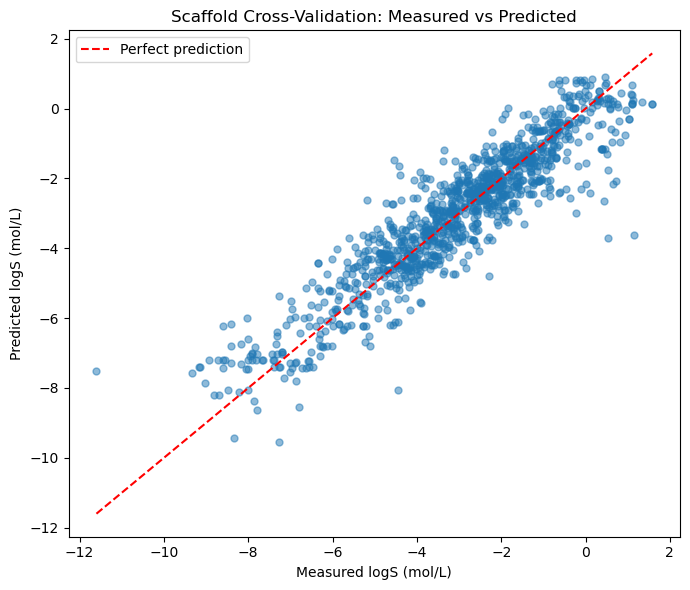

In [65]:

from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

cv = GroupKFold(n_splits=5)

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Every molecule receives an out-of-fold prediction
y_pred_scaffold_cv = cross_val_predict(
    model,
    X,
    y,
    groups=scaffolds,
    cv=cv,
    n_jobs=-1
)

# Calculate pooled metrics across all molecules
print("Pooled MAE:", mean_absolute_error(y, y_pred_scaffold_cv))
print("Pooled RMSE:", np.sqrt(mean_squared_error(y, y_pred_scaffold_cv)))
print("Pooled R²:", r2_score(y, y_pred_scaffold_cv))

# Plot measured versus predicted aqueous solubility
plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    y_pred_scaffold_cv,
    alpha=0.5,
    s=25
)

limits = [
    min(y.min(), y_pred_scaffold_cv.min()),
    max(y.max(), y_pred_scaffold_cv.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Measured logS (mol/L)")
plt.ylabel("Predicted logS (mol/L)")
plt.title("Scaffold Cross-Validation: Measured vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()


In [66]:

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a table containing the predictions
error_df = pd.DataFrame({
    "SMILES": data["smiles"].to_numpy(),
    "Measured logS": np.asarray(y),
    "Predicted logS": y_pred_scaffold_cv,
    "Scaffold": scaffolds.to_numpy()
})

# Calculate absolute prediction errors
error_df["Absolute Error"] = abs(
    error_df["Measured logS"] - error_df["Predicted logS"]
)

# Classify molecules into three structural groups
error_df["Group"] = np.select(
    [
        error_df["Scaffold"] == "",
        error_df["Scaffold"] == "c1ccccc1"
    ],
    [
        "Acyclic",
        "Benzene scaffold"
    ],
    default="Other scaffolds"
)

# Calculate performance for each group
results = []

for group, subset in error_df.groupby("Group"):
    results.append({
        "Group": group,
        "Molecules": len(subset),
        "MAE": mean_absolute_error(
            subset["Measured logS"],
            subset["Predicted logS"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            subset["Measured logS"],
            subset["Predicted logS"]
        )),
        "R²": r2_score(
            subset["Measured logS"],
            subset["Predicted logS"]
        )
    })

group_results = pd.DataFrame(results)
print(group_results.to_string(index=False))


           Group  Molecules      MAE     RMSE       R²
         Acyclic        317 0.549277 0.802054 0.806272
Benzene scaffold        254 0.604357 0.755199 0.728220
 Other scaffolds        557 0.673204 0.885851 0.834760


In [67]:

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a table containing the predictions
error_df = pd.DataFrame({
    "SMILES": data["smiles"].to_numpy(),
    "Measured logS": np.asarray(y),
    "Predicted logS": y_pred_scaffold_cv,
    "Scaffold": scaffolds.to_numpy()
})

# Calculate absolute prediction errors
error_df["Absolute Error"] = abs(
    error_df["Measured logS"] - error_df["Predicted logS"]
)

# Classify molecules into three structural groups
error_df["Group"] = np.select(
    [
        error_df["Scaffold"] == "",
        error_df["Scaffold"] == "c1ccccc1"
    ],
    [
        "Acyclic",
        "Benzene scaffold"
    ],
    default="Other scaffolds"
)

# Calculate performance for each group
results = []

for group, subset in error_df.groupby("Group"):
    results.append({
        "Group": group,
        "Molecules": len(subset),
        "MAE": mean_absolute_error(
            subset["Measured logS"],
            subset["Predicted logS"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            subset["Measured logS"],
            subset["Predicted logS"]
        )),
        "R²": r2_score(
            subset["Measured logS"],
            subset["Predicted logS"]
        )
    })

group_results = pd.DataFrame(results)
print(group_results.to_string(index=False))


           Group  Molecules      MAE     RMSE       R²
         Acyclic        317 0.549277 0.802054 0.806272
Benzene scaffold        254 0.604357 0.755199 0.728220
 Other scaffolds        557 0.673204 0.885851 0.834760


In [68]:

worst_predictions = error_df.nlargest(
    10, "Absolute Error"
)

print(
    worst_predictions[
        ["SMILES", "Measured logS",
         "Predicted logS", "Absolute Error", "Group"]
    ].to_string(index=False)
)


                                                    SMILES  Measured logS  Predicted logS  Absolute Error           Group
                              CNC(=O)C(C)SCCSP(=O)(OC)(OC)          1.144       -3.612500        4.756500         Acyclic
                          CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl          0.523       -3.710860        4.233860         Acyclic
     Clc1c(Cl)c(Cl)c(c(Cl)c1Cl)c2c(Cl)c(Cl)c(Cl)c(Cl)c2Cl         -11.600       -7.514230        4.085770 Other scaffolds
OC(CC(c1ccccc1)c3c(O)c2ccccc2oc3=O)c4ccc(cc4)c5ccc(Br)cc5          -4.445       -8.064230        3.619230 Other scaffolds
                                     CCNc1nc(Cl)nc(NCC)n1          -4.550       -1.464367        3.085633 Other scaffolds
                                          CCOP(=O)(OCC)OCC          0.430       -2.653852        3.083852         Acyclic
                                 CNC(=O)C=C(C)OP(=O)(OC)OC          0.651       -2.150806        2.801806         Acyclic
                        

In [69]:

from rdkit import Chem
import pandas as pd

# Identify molecules containing phosphorus
def contains_phosphorus(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return any(
        atom.GetAtomicNum() == 15
        for atom in mol.GetAtoms()
    )

error_df["Contains P"] = error_df["SMILES"].apply(
    contains_phosphorus
)

# Compare average errors
phosphorus_results = error_df.groupby(
    "Contains P"
).agg(
    Molecules=("Absolute Error", "size"),
    MAE=("Absolute Error", "mean"),
    Median_Error=("Absolute Error", "median")
)

print(phosphorus_results)


            Molecules       MAE  Median_Error
Contains P                                   
False            1085  0.603920      0.481146
True               43  1.101155      0.749610


In [70]:

# Compare phosphorus-related errors within scaffold groups
diagnostic = (
    error_df
    .groupby(["Group", "Contains P"])
    .agg(
        Molecules=("Absolute Error", "size"),
        MAE=("Absolute Error", "mean"),
        Median_Error=("Absolute Error", "median")
    )
    .reset_index()
)

print(diagnostic.to_string(index=False))


           Group  Contains P  Molecules      MAE  Median_Error
         Acyclic       False        300 0.487867      0.398272
         Acyclic        True         17 1.632999      1.372181
Benzene scaffold       False        239 0.591591      0.509640
Benzene scaffold        True         15 0.807769      0.749610
 Other scaffolds       False        546 0.673082      0.518181
 Other scaffolds        True         11 0.679284      0.556817


In [71]:

from pathlib import Path
import joblib
from sklearn.ensemble import RandomForestRegressor

# Train the final model on the full ESOL dataset.
# Cross-validation has already been performed.
final_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, y)

# Save the trained model and feature names.
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": final_model,
        "features": feature_cols
    },
    model_dir / "esol_random_forest.joblib"
)

print("Model saved successfully!")


Model saved successfully!
